# Channel LES 검증 시각화 — 캠페인 전환형 (`CAMPAIGN = "re180_64" | "re360_vreman"`)

`../log/les64_<case>.log` 모니터 이력(중간 과정)과 `../stats_les64_<case>/channel_stats_*.dat` 최신 통계(결과)를
DNS 참조(`../stats_re180_ref/` 256³, Re$_\tau$ 180.9)·MKM 1999(`ref_mean_180.txt`, `ref_fluc_180.txt`)와 겹친다.
실행하면 같은 폴더에 `les_*.png` 로 저장되고 **화면에도 같이 뜬다** (노트북 inline, 배치는 Agg).
통계가 아직 없는 진행 중 런은 모니터 그림에만 나온다. 통계 누적 구간은 stats 헤더 `step`·`samples` 에서
복원(시작 = step − samples + 1)해 모니터 그림에 음영으로 표시한다.

| 그림 | 내용 | 판정 (docs/Design/20261006_les_design.md §4) |
|---|---|---|
| les_monitor | Re$_\tau$(t), −dPdx, dt, div + 통계 구간 띠 | 목표 180 ±3% 띠에 정착 |
| les_mean | U⁺(z⁺) vs DNS·MKM·로그법칙 | 로그영역 RMS 차 < 0.3 |
| les_rms | u′v′w′ rms⁺, −uw⁺ | 피크 ±10% |
| les_nut | ⟨ν_t⟩/ν (선형·log-log + y³ 안내선) | 벽 근처 멱지수 (Vreman: y¹ 예상) |
| les_shear | 총전단 수지 ν_eff dU/dz − uw vs u_τ²(1−z/δ) | 수지 닫힘 |


In [25]:
import glob, re, os
import numpy as np
import matplotlib
try:
    get_ipython().run_line_magic("matplotlib", "inline")
except NameError:
    matplotlib.use("Agg")
import matplotlib.pyplot as plt

HERE = os.path.dirname(os.path.abspath("__file__")) if "__file__" in dir() else os.getcwd()
APP = os.path.abspath(os.path.join(HERE, ".."))
# ── 캠페인 전환 — 여기만 바꾸면 된다 ─────────────────────────────────────
#   "re180_64"     : 우리가 고른 격자 (Re_τ 180, 64³, 4π×2π×2), 자체 DNS 256³ 와 비교
#   "re180_96"     : 96³ 격자 민감도 (mirror 벽; 64³ 과 같은 박스·γ_z, 수평 해상도만 1.5 배)
#   "re360_vreman" : **Vreman (2004) Phys.Fluids 16,3670 §V.B 조건 1:1**
#                    Re_τ 360, 6H×2H×2H, 47×63×47, 5번째 z점 y⁺=11, 통계 10~30 H/u_τ
#                    (단 구동은 CFR — 논문은 constant pressure gradient. 사용자 결정 2026-10-06)
CAMPAIGN = "re360_vreman"

CAMPAIGNS = {
    "re180_64": dict(
        target_re_tau=180.0, reynolds_bulk=2857.0,
        log_pattern="les64_{key}.log", stats_pattern="stats_les64_{key}",
        dns_glob="stats_re180_ref/channel_stats_*.dat", dns_label="DNS 256^3",
        reference_suffix="180", reference_label="MKM 1999 (Re_tau 182)",
        grid_label="64^3, 4pi x 2pi x 2"),
    "re180_96": dict(   # 96³ 격자 민감도 (mirror 벽): 수평만 1.5 배 (Δx⁺≈23, Δy⁺≈12), γ_z 3.0 유지
        target_re_tau=180.0, reynolds_bulk=2857.0,
        log_pattern="les96_{key}.log", stats_pattern="stats_les96_{key}",
        dns_glob="stats_re180_ref/channel_stats_*.dat", dns_label="DNS 256^3",
        reference_suffix="180", reference_label="MKM 1999 (Re_tau 182)",
        grid_label="96^3, 4pi x 2pi x 2"),
    "re360_vreman": dict(
        target_re_tau=360.0, reynolds_bulk=6198.0,
        log_pattern="les360_{key}.log", stats_pattern="stats_re360_les_{key}",
        # Re_τ 360 자체 DNS 는 없다 — 논문이 쓴 Hu&Sandham(Re_τ 360) 은 소스가 사라졌고,
        # 논문 본문(지면 3676)이 "Moser et al. Re_τ=395 와 collapse" 라고 밝혀 MKM 395 로 대체.
        dns_glob=None, dns_label="MKM chan395 (Re_tau 392)",
        reference_suffix="395", reference_label="MKM 1999 chan395 (Re_tau 392)",
        grid_label="47 x 63 x 47, 6H x 2H x 2H (Vreman 2004 sec.V.B)"),
}
C = CAMPAIGNS[CAMPAIGN]
TARGET_RE_TAU = C["target_re_tau"]
NU = 1.0 / C["reynolds_bulk"]   # δ=1, U_b=1 → ν = U_b δ/Re_b
DNS_LABEL = C["dns_label"]
print(f"CAMPAIGN = {CAMPAIGN}   target Re_tau {TARGET_RE_TAU:.0f}, "
      f"Re_b {C['reynolds_bulk']:.0f}, grid {C['grid_label']}")

cases = [
    dict(label="no-model (0-model)", key="none", color="tab:gray"),
    dict(label="Vreman C_s=0.12 (Fortran)", key="vreman012", color="tab:red"),
    dict(label="Vreman C_s=0.17 (= paper c=0.07)", key="vreman017", color="tab:blue"),
    # mirror 벽(2차: 거울 ghost + 닫기 B−=A + 벽면 u_τ 자) — value 벽은 첫 셀 U⁺=2z⁺ 인공물 (les_design.md §9).
    # 해당 캠페인에 런이 없으면 자동으로 건너뛴다 (stats 없음).
    dict(label="no-model, mirror wall", key="none_mirror", color="k"),
    dict(label="Vreman C_s=0.12, mirror wall", key="vreman012_mirror", color="tab:orange"),
    # WALE (Nicoud & Ducros 1999, C_w 0.5) — les_design.md §11. 벽 근처 ν_t ∝ y³ 가 판정 항목.
    dict(label="WALE C_w=0.5, mirror wall", key="wale_mirror", color="tab:green"),
]

def read_monitor(path):
    rows = []
    for ln in open(path):
        if re.match(r"^\s+\d+\s", ln):
            v = ln.split()
            if len(v) >= 9: rows.append([float(x) for x in v[:9]])
    return np.array(rows) if rows else None

def read_stats(path):
    meta = {}
    for ln in open(path):
        if ln.startswith("#"):
            for k, v in re.findall(r"(\w+)=([0-9.eE+-]+)", ln): meta[k] = float(v)
    d = np.loadtxt(path, comments="#")
    s = dict(z=d[:, 0], zp=d[:, 1], U=d[:, 2], Up=d[:, 3], urms=d[:, 4], vrms=d[:, 5], wrms=d[:, 6], uw=d[:, 7])
    s["nut"] = d[:, 8] if d.shape[1] > 8 else np.zeros(len(d))
    return meta, s

def half_profile(s):  # 하반 + 상반 대칭 평균 (uw 는 반대칭)
    nz = len(s["z"]); k = np.arange(nz // 2)
    sym = lambda a, sign=1: 0.5 * (a[k] + sign * a[nz - 1 - k])
    return dict(z=s["z"][k], zp=s["zp"][k], Up=sym(s["Up"]), U=sym(s["U"]), urms=sym(s["urms"]), vrms=sym(s["vrms"]),
                wrms=sym(s["wrms"]), uw=sym(s["uw"], -1), nut=sym(s["nut"]))

for c in cases:
    logs = sorted(glob.glob(f"{APP}/log/" + C["log_pattern"].format(key=c["key"])))
    c["monitor"] = read_monitor(logs[-1]) if logs else None
    stats = sorted(glob.glob(f"{APP}/" + C["stats_pattern"].format(key=c["key"])
                             + "/channel_stats_*.dat"))
    c["stats_path"] = stats[-1] if stats else None
    if stats:
        c["meta"], c["stats"] = read_stats(stats[-1]); c["half"] = half_profile(c["stats"])
        c["window"] = (c["meta"]["step"] - c["meta"]["samples"] + 1, c["meta"]["step"])
    else:
        c["meta"] = c["stats"] = c["half"] = None; c["window"] = None
    print(f"[{c['key']}] monitor rows: {0 if c['monitor'] is None else len(c['monitor'])}, "
          f"stats: {os.path.basename(c['stats_path']) if c['stats_path'] else '없음'}"
          + (f" (Re_tau {c['meta']['Re_tau']:.2f}, samples {int(c['meta']['samples'])}, 누적 step {int(c['window'][0])}~{int(c['window'][1])})" if c['meta'] else ""))

# 참조 MKM (벽단위 정규화 완료). MKM: y = 벽수직(우리 z), v = 벽수직(우리 w), w = 스팬(우리 v)
suffix = C["reference_suffix"]
mkm_mean = np.loadtxt(f"{HERE}/ref_mean_{suffix}.txt", comments="%")  # y/δ, y+, U+, dU/dy, W, P
mkm_fluc = np.loadtxt(f"{HERE}/ref_fluc_{suffix}.txt", comments="%")  # y/δ, y+, u'u', v'v', w'w', u'v', u'w', v'w', k
mkm = dict(zp=mkm_mean[:, 1], Up=mkm_mean[:, 2], urms=np.sqrt(mkm_fluc[:, 2]), wrms=np.sqrt(mkm_fluc[:, 3]),
           vrms=np.sqrt(mkm_fluc[:, 4]), uw=-mkm_fluc[:, 5])   # u'v' → −uw⁺

# 기준선(dns): 자체 DNS 가 있으면 그것, 없으면 **MKM 을 그 자리에** 넣는다.
# MKM 은 이미 u_τ 로 정규화돼 있으므로 u_tau=1 로 두면 하류 코드(÷u_tau)가 그대로 맞는다.
if C["dns_glob"]:
    ref_paths = sorted(glob.glob(f"{APP}/{C['dns_glob']}"))
    dns_meta, dns_stats = read_stats(ref_paths[-1]); dns = half_profile(dns_stats)
    print(f"기준선: {DNS_LABEL} — {os.path.basename(ref_paths[-1])}  Re_tau={dns_meta['Re_tau']:.2f}")
else:
    dns_meta = dict(Re_tau=float(mkm_mean[-1, 1] / mkm_mean[-1, 0]), u_tau=1.0)
    dns = dict(z=mkm_mean[:, 0], zp=mkm["zp"], U=mkm["Up"], Up=mkm["Up"],
               urms=mkm["urms"], vrms=mkm["vrms"], wrms=mkm["wrms"], uw=-mkm["uw"],
               nut=np.zeros(len(mkm_mean)))
    print(f"기준선: {DNS_LABEL} (자체 DNS 없음 — 참조 DNS 를 기준선으로)  "
          f"Re_tau={dns_meta['Re_tau']:.2f}")
# ★ 오차·±3% 띠의 기준 = 기준선 DNS 의 Re_tau (사용자 결정 2026-10-07: 360 캠페인은 MKM 392 기준으로 통일).
#   TARGET_RE_TAU(캠페인 목표)는 덱 설계 메모로만 남긴다.
BASE_RE_TAU = dns_meta["Re_tau"]


CAMPAIGN = re360_vreman   target Re_tau 360, Re_b 6198, grid 47 x 63 x 47, 6H x 2H x 2H (Vreman 2004 sec.V.B)
[none] monitor rows: 301, stats: channel_stats_00030000.dat (Re_tau 386.43, samples 21001, 누적 step 9000~30000)
[vreman012] monitor rows: 301, stats: channel_stats_00030000.dat (Re_tau 367.94, samples 21001, 누적 step 9000~30000)
[vreman017] monitor rows: 301, stats: channel_stats_00030000.dat (Re_tau 351.94, samples 21001, 누적 step 9000~30000)
[none_mirror] monitor rows: 301, stats: channel_stats_00030000.dat (Re_tau 392.71, samples 21001, 누적 step 9000~30000)
[vreman012_mirror] monitor rows: 301, stats: channel_stats_00030000.dat (Re_tau 372.95, samples 21001, 누적 step 9000~30000)
[wale_mirror] monitor rows: 0, stats: 없음
기준선: MKM chan395 (Re_tau 392) (자체 DNS 없음 — 참조 DNS 를 기준선으로)  Re_tau=392.24


## 1. 중간 과정 — 모니터 이력 (★ 먼저: 살아 있나, Re_τ 정착했나, 통계 구간이 정상상태 안인가)

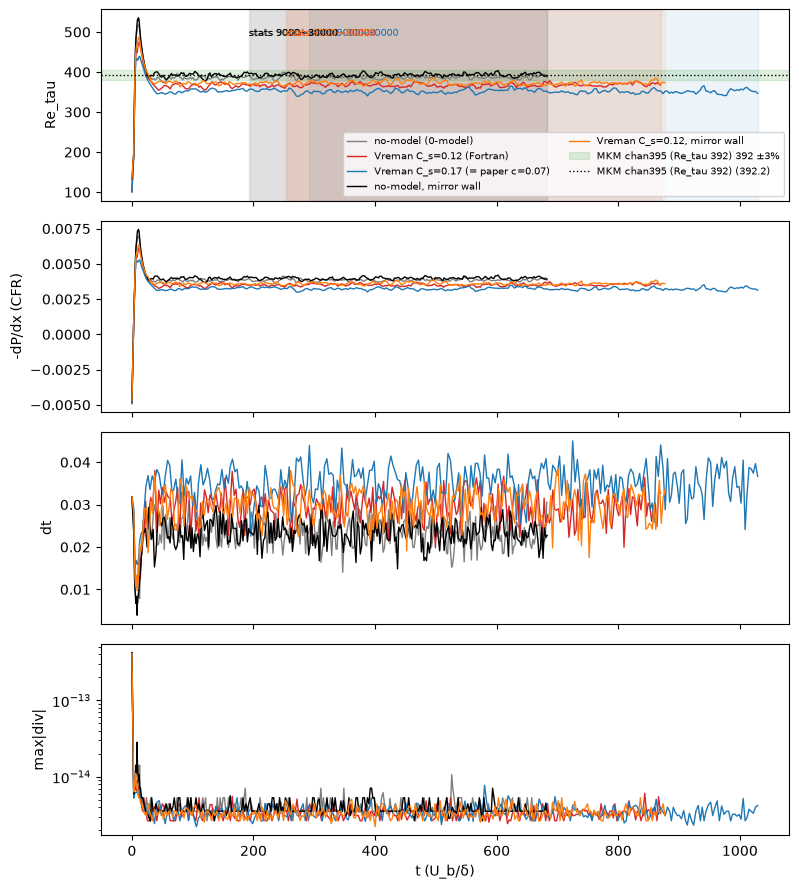

In [26]:
fig, axes = plt.subplots(4, 1, figsize=(8, 9), sharex=True)
for c in cases:
    m = c["monitor"]
    if m is None: continue
    step, t, dt, bulk, div, u_tau, re_tau, dpdx = m[:, 0], m[:, 1], m[:, 2], m[:, 3], m[:, 4], m[:, 5], m[:, 6], m[:, 7]
    axes[0].plot(t, re_tau, color=c["color"], lw=1, label=c["label"])
    axes[1].plot(t, dpdx, color=c["color"], lw=1)
    axes[2].plot(t, dt, color=c["color"], lw=1)
    axes[3].semilogy(t, div, color=c["color"], lw=1)
    if c["window"]:
        t0, t1 = np.interp([c["window"][0], c["window"][1]], step, t)
        axes[0].axvspan(t0, t1, color=c["color"], alpha=0.08)
        axes[0].text(t0, BASE_RE_TAU * 1.25, f"stats {int(c['window'][0])}~{int(c['window'][1])}", color=c["color"], fontsize=7)
axes[0].axhspan(BASE_RE_TAU * 0.97, BASE_RE_TAU * 1.03, color="tab:green", alpha=0.15, label=f"{DNS_LABEL} {BASE_RE_TAU:.0f} ±3%")
axes[0].axhline(dns_meta["Re_tau"], color="k", ls=":", lw=1, label=f"{DNS_LABEL} ({dns_meta['Re_tau']:.1f})")
axes[0].set_ylabel("Re_tau"); axes[0].legend(fontsize=7, ncol=2)
axes[1].set_ylabel("-dP/dx (CFR)"); axes[2].set_ylabel("dt"); axes[3].set_ylabel("max|div|"); axes[3].set_xlabel("t (U_b/δ)")
plt.tight_layout(); plt.savefig(f"{HERE}/les_monitor_{CAMPAIGN}.png", dpi=130); plt.show()


## 2. 결과 — 평균 속도 U⁺(z⁺)

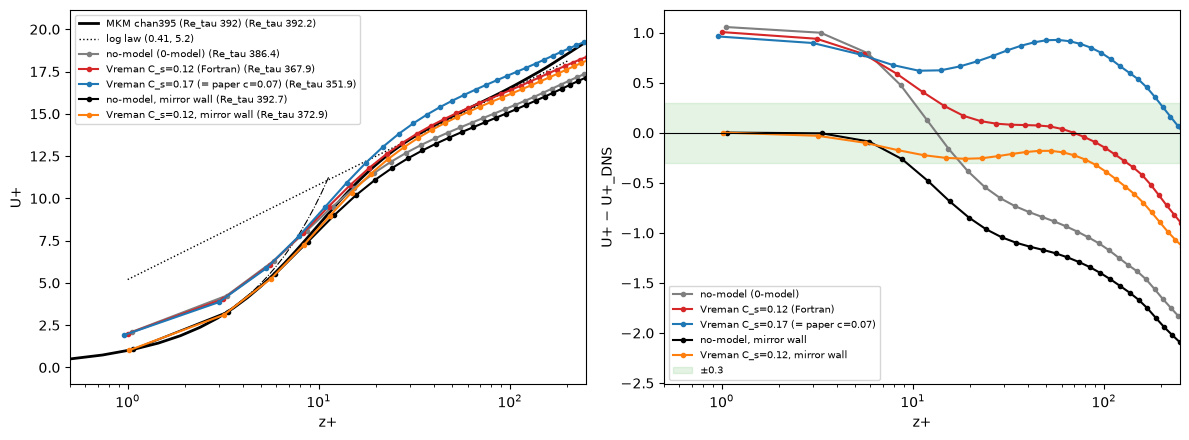

In [27]:
have = [c for c in cases if c["half"] is not None]
if not have:
    print("통계 파일 없음 — 런 진행 중 (stats_write_interval 뒤 다시 실행)")
else:
    fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
    zp = np.logspace(0, np.log10(200), 60)
    # ★ 참조 곡선은 **왼쪽(절대 U+) 패널에만**. 오른쪽은 차이 플롯이라 여기에 그리면
    #   의미가 없을 뿐 아니라 y축이 ~20 까지 늘어나 정작 봐야 할 ±0.3 띠를 뭉갠다.
    a = ax[0]
    a.semilogx(dns["zp"], dns["Up"], "k-", lw=2, label=f"{DNS_LABEL} (Re_tau {dns_meta['Re_tau']:.1f})")
    if C["reference_suffix"] not in DNS_LABEL:   # 기준선이 MKM 자신이면 중복 생략
        a.semilogx(mkm["zp"], mkm["Up"], "k--", lw=1, label=C["reference_label"])
    a.semilogx(zp, np.log(zp) / 0.41 + 5.2, "k:", lw=1, label="log law (0.41, 5.2)")
    a.semilogx(zp[zp < 12], zp[zp < 12], "k-.", lw=0.8)
    for c in have:
        h = c["half"]
        ax[0].semilogx(h["zp"], h["Up"], "o-", ms=3, color=c["color"], label=f"{c['label']} (Re_tau {c['meta']['Re_tau']:.1f})")
        ref_i = np.interp(h["zp"], dns["zp"], dns["Up"])
        ax[1].semilogx(h["zp"], h["Up"] - ref_i, "o-", ms=3, color=c["color"], label=c["label"])
    ax[0].set_xlabel("z+"); ax[0].set_ylabel("U+"); ax[0].legend(fontsize=7); ax[0].set_xlim(0.5, 250)
    ax[1].axhline(0, color="k", lw=0.8); ax[1].axhspan(-0.3, 0.3, color="tab:green", alpha=0.12, label="±0.3")
    ax[1].set_xlabel("z+"); ax[1].set_ylabel("U+ − U+_DNS"); ax[1].legend(fontsize=7); ax[1].set_xlim(0.5, 250)
    plt.tight_layout(); plt.savefig(f"{HERE}/les_mean_{CAMPAIGN}.png", dpi=130); plt.show()


## 3. 결과 — 2차 통계 (rms⁺, −uw⁺)

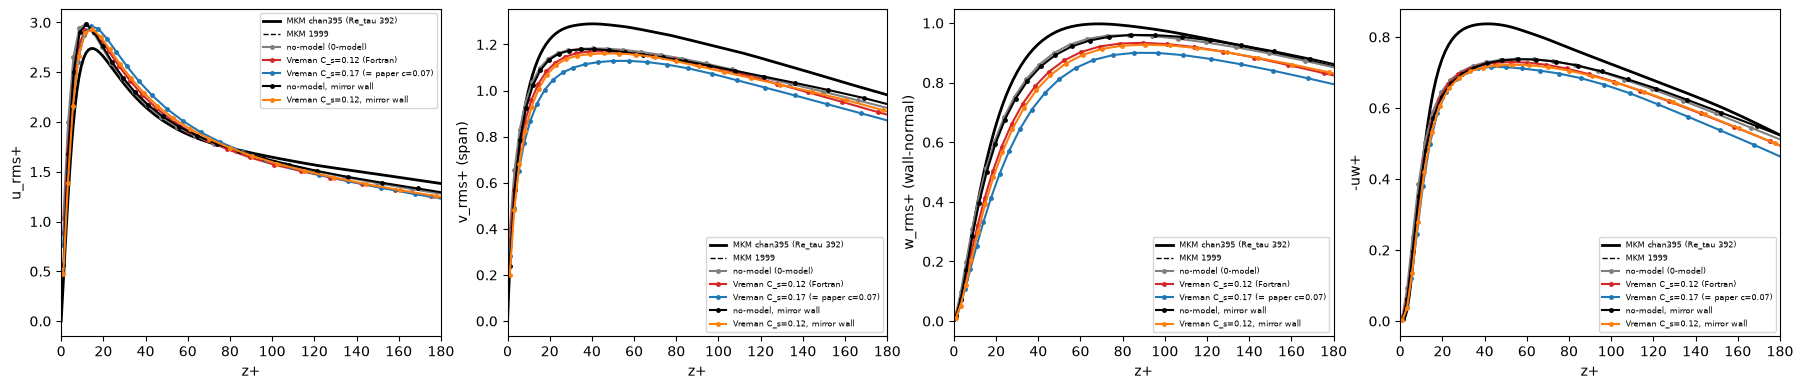

In [28]:
if have:
    fig, ax = plt.subplots(1, 4, figsize=(18, 4))
    panels = [("urms", "u_rms+"), ("vrms", "v_rms+ (span)"), ("wrms", "w_rms+ (wall-normal)"), ("uw", "-uw+")]
    for a, (key, lab) in zip(ax, panels):
        sign = -1 if key == "uw" else 1
        a.plot(dns["zp"], sign * dns[key] / (dns_meta["u_tau"] ** (2 if key == "uw" else 1)), "k-", lw=2, label=DNS_LABEL)
        a.plot(mkm["zp"], mkm[key] if key != "uw" else mkm["uw"], "k--", lw=1, label="MKM 1999")
        for c in have:
            h = c["half"]; ut = c["meta"]["u_tau"]
            a.plot(h["zp"], sign * h[key] / (ut ** (2 if key == "uw" else 1)), "o-", ms=2.5, color=c["color"], label=c["label"])
        a.set_xlabel("z+"); a.set_ylabel(lab); a.set_xlim(0, 180); a.legend(fontsize=6)
    plt.tight_layout(); plt.savefig(f"{HERE}/les_rms_{CAMPAIGN}.png", dpi=130); plt.show()


## 4. 결과 — 와점성 ⟨ν_t⟩/ν 와 총전단 수지

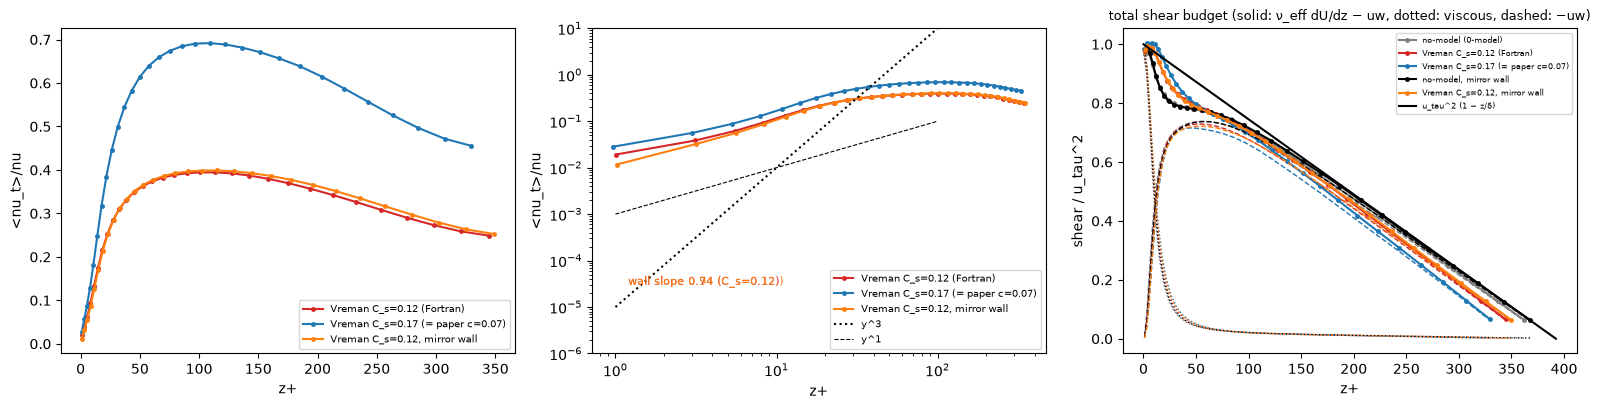

In [29]:
if have:
    fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
    for c in have:
        h = c["half"]
        if np.max(h["nut"]) <= 0: continue
        ax[0].plot(h["zp"], h["nut"], "o-", ms=2.5, color=c["color"], label=c["label"])
        ax[1].loglog(h["zp"], np.maximum(h["nut"], 1e-12), "o-", ms=2.5, color=c["color"], label=c["label"])
        msk = (h["zp"] > 1) & (h["zp"] < 10) & (h["nut"] > 1e-12)
        if msk.sum() > 3:
            slope = np.polyfit(np.log(h["zp"][msk]), np.log(h["nut"][msk]), 1)[0]
            ax[1].text(1.2, 3e-5 * (10 if "0.17" in c["label"] else 1), f"wall slope {slope:.2f} ({c['label'].split(' ')[1]})", color=c["color"], fontsize=8)
    zp = np.logspace(0, 2, 30)
    ax[1].loglog(zp, 1e-5 * zp ** 3, "k:", label="y^3"); ax[1].loglog(zp, 1e-3 * zp, "k--", lw=0.8, label="y^1")
    ax[0].set_xlabel("z+"); ax[0].set_ylabel("<nu_t>/nu"); ax[0].legend(fontsize=7)
    ax[1].set_xlabel("z+"); ax[1].set_ylabel("<nu_t>/nu"); ax[1].legend(fontsize=7); ax[1].set_ylim(1e-6, 10)
    # 총전단 수지: ν(1+ν_t/ν) dU/dz − <uw>  vs  u_τ²(1 − z/δ)   (z = 벽 거리, δ = 1)
    for c in have:
        h = c["half"]; ut = c["meta"]["u_tau"]
        dUdz = np.gradient(h["U"], h["z"])
        total = NU * (1 + h["nut"]) * dUdz - h["uw"]
        ax[2].plot(h["zp"], total / ut**2, "o-", ms=2.5, color=c["color"], label=c["label"])
        ax[2].plot(h["zp"], NU * dUdz / ut**2, ":", color=c["color"], lw=1)
        ax[2].plot(h["zp"], -h["uw"] / ut**2, "--", color=c["color"], lw=1)
    ax[2].plot(dns["zp"], 1 - dns["z"], "k-", lw=1.5, label="u_tau^2 (1 − z/δ)")
    ax[2].set_xlabel("z+"); ax[2].set_ylabel("shear / u_tau^2"); ax[2].legend(fontsize=6)
    ax[2].set_title("total shear budget (solid: ν_eff dU/dz − uw, dotted: viscous, dashed: −uw)", fontsize=9)
    plt.tight_layout(); plt.savefig(f"{HERE}/les_nut_{CAMPAIGN}.png", dpi=130); plt.show()


## 5. 요약 표 — 판정 지표

In [30]:
if have:
    # ★ err% 의 분모 = 기준선 DNS Re_tau (BASE_RE_TAU). 캠페인 목표(TARGET_RE_TAU)와 다르면 함께 적는다.
    print(f"기준선 {DNS_LABEL}: Re_tau={BASE_RE_TAU:.2f}  (덱 목표 {TARGET_RE_TAU:.0f}; err% 와 ±3% 띠는 기준선 기준)")
    print(f"{'case':<32} {'Re_tau':>7} {'err%':>6} {'U+ logRMS':>10} {'U+ bias':>8} {'urms pk':>8} {'vrms pk':>8} {'wrms pk':>8} {'-uw pk':>7} {'max nut/nu':>10} {'nut~y^n':>8} {'(pts)':>6}")
    rp = lambda key: dns[key].max() / dns_meta["u_tau"]
    print(f"{DNS_LABEL:<32} {dns_meta['Re_tau']:7.2f} {'':>6} {'':>10} {'':>8} {rp('urms'):8.3f} {rp('vrms'):8.3f} {rp('wrms'):8.3f} {(-dns['uw']).max()/dns_meta['u_tau']**2:7.3f}")
    for c in have:
        h = c["half"]; m = c["meta"]; ut = m["u_tau"]; retau = m["Re_tau"]
        mask = (h["zp"] > 30) & (h["zp"] < 0.3 * retau)
        Uref = np.interp(h["zp"][mask], dns["zp"], dns["Up"])
        logrms = np.sqrt(np.mean((h["Up"][mask] - Uref) ** 2)) if mask.sum() > 2 else float("nan")
        bias = np.mean(h["Up"][mask] - Uref) if mask.sum() > 2 else float("nan")
        # nu_t 벽 멱지수: LES 격자는 z+ 1~10 에 셀이 3~4개뿐이라 창을 넓히고 **점 수를 같이 찍는다**
        # (64^3 Re_tau 180 에서는 넉넉했지만 47x63x47 Re_tau 360 에서는 5번째 점이 이미 z+ 11).
        msk = (h["zp"] > 0.5) & (h["zp"] < 15) & (h["nut"] > 1e-12)
        points = int(msk.sum())
        slope = (np.polyfit(np.log(h["zp"][msk]), np.log(h["nut"][msk]), 1)[0]
                 if points >= 3 else float("nan"))
        print(f"{c['label']:<32} {retau:7.2f} {100*(retau/BASE_RE_TAU-1):6.2f} {logrms:10.3f} {bias:8.3f} "
              f"{h['urms'].max()/ut:8.3f} {h['vrms'].max()/ut:8.3f} {h['wrms'].max()/ut:8.3f} "
              f"{(-h['uw']).max()/ut**2:7.3f} {h['nut'].max():10.3f} {slope:8.2f} {points:6d}")
    print(f"판정: Re_tau 기준선 {BASE_RE_TAU:.0f} ±3%, U+ logRMS < 0.3, rms 피크 ±10%, "
          "no-model 대비 개선 여부")
    print("  (nut~y^n 은 점 수가 5 미만이면 기울기 신뢰도가 낮다 — 격자 한계이지 모델 문제가 아니다)")


기준선 MKM chan395 (Re_tau 392): Re_tau=392.24  (덱 목표 360; err% 와 ±3% 띠는 기준선 기준)
case                              Re_tau   err%  U+ logRMS  U+ bias  urms pk  vrms pk  wrms pk  -uw pk max nut/nu  nut~y^n  (pts)
MKM chan395 (Re_tau 392)          392.24                               2.739    1.289    0.997   0.837
no-model (0-model)                386.43  -1.48      0.953   -0.943    2.986    1.183    0.960   0.739      0.000      nan      0
Vreman C_s=0.12 (Fortran)         367.94  -6.19      0.079    0.006    2.927    1.170    0.934   0.730      0.394     0.83      6
Vreman C_s=0.17 (= paper c=0.07)  351.94 -10.27      0.879    0.878    2.964    1.129    0.900   0.716      0.692     0.80      6
no-model, mirror wall             392.71   0.12      1.266   -1.261    2.983    1.179    0.960   0.737      0.000      nan      0
Vreman C_s=0.12, mirror wall      372.95  -4.92      0.250   -0.240    2.932    1.161    0.928   0.722      0.399     1.00      6
판정: Re_tau 기준선 392 ±3%, U+ logRMS < 0.3